In [1]:

# Install Unsloth for Google Colab
!pip install --upgrade pip

!pip install unsloth
!pip install --no-deps unsloth_zoo

# Hugging Face ecosystem
!pip install -U transformers datasets accelerate peft trl

# Quantization support
!pip install bitsandbytes

# Additional utilities
!pip install sentencepiece protobuf
!pip install gguf msgspec blake3


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 61.6 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.2.2
    Uninstalling pip-26.2.2:
      Successfully uninstalled pip-26.2.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.1/29.1 MB 141.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 130.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 52.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 57.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 116.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 131.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 96.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 135.5 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
  Attempting unin

In [9]:
from unsloth import FastModel
import torch

model, tokenizer = FastModel.from_pretrained(
    model_name="unsloth/gemma-3-4b-it",
    max_seq_length=2048,
    load_in_4bit=True,
    dtype=None,
)

print("Gemma 3 4B loaded successfully!")
print("Tokenizer:", tokenizer)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


/usr/local/lib/python3.13/dist-packages/transformers/configuration_utils.py:723: FutureWarning: `rope_scaling` is deprecated and will be removed in a future version. Set `rope_parameters` instead, with `rope_type` and `rope_theta` included.
  warnings.warn(


Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.2: Fast Gemma3 patching. Transformers: 5.22.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
	257176: AddedToken("<unused1274>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	257177: AddedToken("<unused1275>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	257178: AddedToken("<unused1276>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	257179: AddedToken("<unused1277>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	257180: AddedToken("<unused1278>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	257181: AddedToken("<unused1279>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	257182: AddedToken("<unused1280>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	257183: AddedToken("<unused1281>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	257184: Adde

In [5]:
from google.colab import files

uploaded = files.upload()

Saving dataasilida_cleaned.csv to dataasilida_cleaned.csv


In [6]:

import pandas as pd
from datasets import Dataset, DatasetDict

# Read CSV with corrected column names
df = pd.read_csv(
    "dataasilida_cleaned.csv",
    header=None,
    skiprows=1,
    names=["input", "output"]
)

# Remove missing values
df = df.dropna(subset=["input", "output"]).copy()

# Clean whitespace
df["input"] = df["input"].astype(str).str.strip()
df["output"] = df["output"].astype(str).str.strip()

# Remove empty records
df = df[(df["input"] != "") & (df["output"] != "")]

# Remove duplicate Q&A pairs
df = df.drop_duplicates(subset=["input", "output"])

# Reset index
df = df.reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nSample:")
display(df.head(5))


Dataset shape: (512, 2)

Missing values:
input     0
output    0
dtype: int64

Sample:


,input,output
0,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី,ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ...
1,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ផ្តល់នូ...,លោកអ្នកទទួលបានអត្ថប្រយោជន៍ពីការប្រើប្រាស់ ប័ណ្...
2,តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេ...,លោកអ្នកអាចស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដ...
3,តើខ្ញុំអាចប្រើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ដក...,លោកអ្នកអាចដកប្រាក់បានរហូតដល់ ១០០០០ដុល្លារអាមេរ...
4,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពល...,ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភា...


In [11]:
dataset = DatasetDict({
    "train": Dataset.from_pandas(df, preserve_index=False)
})

print(dataset)
print(dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['input', 'output'],
        num_rows: 512
    })
})
{'input': 'តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី', 'output': 'ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។'}


In [17]:

from datasets import DatasetDict

# First split: 80% train, 20% temporary
split_1 = dataset["train"].train_test_split(
    test_size=0.20,
    seed=42
)

# Second split: Divide temporary data equally
split_2 = split_1["test"].train_test_split(
    test_size=0.50,
    seed=42
)

# Final dataset
dataset = DatasetDict({
    "train": split_1["train"],
    "validation": split_2["train"],
    "test": split_2["test"]
})

# Display dataset sizes
print(dataset)

for split in dataset:
    print(f"{split}: {len(dataset[split])} samples")


DatasetDict({
    train: Dataset({
        features: ['input', 'output', 'text'],
        num_rows: 409
    })
    validation: Dataset({
        features: ['input', 'output', 'text'],
        num_rows: 51
    })
    test: Dataset({
        features: ['input', 'output', 'text'],
        num_rows: 52
    })
})
train: 409 samples
validation: 51 samples
test: 52 samples


In [18]:
print("TRAIN:")
print(dataset["train"][0]["text"][:300])

print("\nVALIDATION:")
print(dataset["validation"][0]["text"][:300])

print("\nTEST:")
print(dataset["test"][0]["text"][:300])

TRAIN:
<bos><start_of_turn>user
តើលក្ខណសម្បត្តិអតិថិជនបែបណា ដើម្បីទទួលបានឥណទានសម្រាប់ទុនបង្វិល<end_of_turn>
<start_of_turn>model
\nមានទីលំនៅអចិន្រ្តៃយ៍ ដោយមានឯកសារបញ្ជាក់អត្តសញ្ញាណពីអាជ្ញាធរក្នុងតំបន់ ដូចជាៈ អត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ សៀវភៅគ្រួសារ លិខិតឆ្លងដែន សៀវភៅស្នាក់នៅ ឬលិខិតផ្សេងទៀតដែលអាចជំនួសបាន ។ 

VALIDATION:
<bos><start_of_turn>user
តើសេវាហិរញ្ញប្បទានពាណិជ្ជកម្មផ្តល់អត្ថប្រយោជន៍អ្វីខ្លះដល់​អតិថិជន និង​សង្គម<end_of_turn>
<start_of_turn>model
\nសម្រាប់​អតិថិជន \n ធានា​បាន​នូវ​ការ​ជឿ​ទុក​ចិត្ត និង​បង្កើត​ទំនាក់​ទំនង​ល្អ​រវាង​ដៃគូ​ពាណិជ្ជកម្ម \n មាន​សុវត្ថិភាព​ខ្ពស់​លើ​មុខ​ជំនួញ \n បង្ក​លក្ខណៈ​ងាយស្រួល​ដល់​

TEST:
<bos><start_of_turn>user
តើឯកសារតម្រូវសម្រាប់សេវាភតិសន្យាហរិញ្ញវត្ថុត្រូវមានអ្វីខ្លះ<end_of_turn>
<start_of_turn>model
ឯកសារតម្រូវសម្រាប់សេវាភតិសន្យាហិរញ្ញវត្ថុមានដូចខាងក្រោម៖ \n សំណើសុំសេវាភតិសន្យាហិរញ្ញវត្ថុ (Application Form)។ \n ឯកសារបញ្ជាក់អត្តសញ្ញាណ និងទីលំនៅ (ID & Residence) របស់អតិថិជន។ \n ឯ


In [19]:

def formatting_prompts_func(examples):

    instructions = examples["input"]
    outputs = examples["output"]

    texts = []

    for instruction, output in zip(instructions, outputs):

        messages = [
            {"role": "user", "content": instruction},
            {"role": "assistant", "content": output}
        ]

        text = tokenizer.apply_chat_template(
            messages,
            add_generation_prompt=False,
            tokenize=False
        )

        texts.append(text)

    return {"text": texts}


# Apply formatting to ALL dataset splits
dataset = dataset.map(
    formatting_prompts_func,
    batched=True
)

# Verify all splits
for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")
    print("Samples:", len(dataset[split]))
    print("Columns:", dataset[split].column_names)
    print("Example:", dataset[split][0]["text"][:200])


Map:   0%|          | 0/409 [00:00<?, ? examples/s]

Map:   0%|          | 0/51 [00:00<?, ? examples/s]

Map:   0%|          | 0/52 [00:00<?, ? examples/s]


TRAIN
Samples: 409
Columns: ['input', 'output', 'text']
Example: <bos><start_of_turn>user
តើលក្ខណសម្បត្តិអតិថិជនបែបណា ដើម្បីទទួលបានឥណទានសម្រាប់ទុនបង្វិល<end_of_turn>
<start_of_turn>model
\nមានទីលំនៅអចិន្រ្តៃយ៍ ដោយមានឯកសារបញ្ជាក់អត្តសញ្ញាណពីអាជ្ញាធរក្នុងតំបន់ ដូចជាៈ

VALIDATION
Samples: 51
Columns: ['input', 'output', 'text']
Example: <bos><start_of_turn>user
តើសេវាហិរញ្ញប្បទានពាណិជ្ជកម្មផ្តល់អត្ថប្រយោជន៍អ្វីខ្លះដល់​អតិថិជន និង​សង្គម<end_of_turn>
<start_of_turn>model
\nសម្រាប់​អតិថិជន \n ធានា​បាន​នូវ​ការ​ជឿ​ទុក​ចិត្ត និង​បង្កើត​ទំន

TEST
Samples: 52
Columns: ['input', 'output', 'text']
Example: <bos><start_of_turn>user
តើឯកសារតម្រូវសម្រាប់សេវាភតិសន្យាហរិញ្ញវត្ថុត្រូវមានអ្វីខ្លះ<end_of_turn>
<start_of_turn>model
ឯកសារតម្រូវសម្រាប់សេវាភតិសន្យាហិរញ្ញវត្ថុមានដូចខាងក្រោម៖ \n សំណើសុំសេវាភតិសន្យាហិ


In [22]:

import torch
from unsloth import FastModel

# Switch model to inference mode
FastModel.for_inference(model)

def ask_gemma(question, max_new_tokens=256, temperature=0.7):

    # Prepare conversation
    messages = [
        {
            "role": "user",
            "content": question
        }
    ]

    # Tokenize input
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    # Generate response
    with torch.inference_mode():
        outputs = model.generate(
            input_ids=inputs,
            max_new_tokens=max_new_tokens,
            temperature=temperature,
            do_sample=(temperature > 0),
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id
        )

    # Extract generated tokens only
    generated_tokens = outputs[0][inputs.shape[-1]:]

    # Decode response
    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()


In [24]:
test_questions = [
    "តើប័ណ្ណឥណពន្ធគឺជាអ្វី?",
    "តើធនាគារ អេស៊ីលីដា ផ្តល់សេវាកម្មអ្វីខ្លះ?",
    "តើម៉ាស៊ីន ATM ប្រើប្រាស់សម្រាប់អ្វី?",
    "តើ​ធ្វើ​ដូចម្តេច​ទើប​ខ្ញុំ​អាច ស្នើសុំ​ប័ណ្ណឥណពន្ធ​យូភីអាយអេស៊ីលីដា ធម្មតា បាន?"
]

for i, question in enumerate(test_questions, 1):
    print(f"\n{'='*50}")
    print(f"Question {i}: {question}")
    print(f"Answer: {ask_gemma(question)}")


Question 1: តើប័ណ្ណឥណពន្ធគឺជាអ្វី?
Answer: ប័ណ្ណឥណពន្ធ (Credit Card) គឺជាឥតិវត្ថុមួយ ដែលអនុញ្ញាតឱ្យអ្នកប្រើប្រាស់អាចទទួរស Loans ឥណ្រីត៍ ដើម្បីទិញสินค้า ឬសេវា ភ្លាមៗ ដោយមិនចាំបាច់មានលុយនៅពេលនោះទេ។ អ្នកនឹងត្រូវបង់ថ្លៃ tilbake ក្រោយមក តាមរយៈការបង់ថ្លៃរាល់ខែ ឬតាមក Schedules ដែលបានកំណត់។

**ខាងក្រោមនេះជាព័ត៌មានសំខាន់ៗអំពីប័ណ្ណឥណពន្ធ:**

*   **របៀប λειτουργ៖** នៅពេលអ្នកប្រើប្រាស់ប័ណ្ណឥណពន្ធដើម្បីទិញអ្វីមួយ អ្នកនឹងទទួលបានលុយឥណ្រីត៍ភ្លាមៗ ហើយអ្នកត្រូវបង់ថ្លៃ tilbake ទៅឱ្យក្រុមហ៊ុនบัណ្ណឥណពន្ធ តាមរយៈការបង់ថ្លៃរាល់ខែ។
*   **អត្រាករ interessi៖** ក្រុមហ៊ុនบัណ្ណឥណពន្ធនឹងគិតអត្រាករ interessi លើលុយឥណ្រីត៍ដែលអ្នកមិនបានបង់ថ្លៃនៅពេលដែលអ្នកមិនអាចបង់ថ្លៃពេញលេញ entro

Question 2: តើធនាគារ អេស៊ីលីដា ផ្តល់សេវាកម្មអ្វីខ្លះ?
Answer: ធនាគារ អេស៊ីលីដា (Acleda Bank) ផ្តល់សេវាកម្មធនាគារជាច្រើនប្រភេទ សម្រាប់អ្នកដែលប្រើប្រាស់ ដូចជា:

**1. សេវាកម្មធនាគារ personale (Personal Banking):**

*   **គណ좌표 (Accounts):** ធនាគារមានប្រភេទគណ좌표ខុសៗគ្នា ដូចជា គណ좌표បញ្ចាំ (Savings Account), គណ좌표ធនាគារ (Current Account), គណ좌표ពិសេស (Sp

In [27]:
from trl import SFTTrainer, SFTConfig

training_args = SFTConfig(
    output_dir="gemma3-khmer-results",

    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,

    num_train_epochs=3,
    learning_rate=2e-4,

    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",

    fp16=not torch.cuda.is_bf16_supported(),
    bf16=torch.cuda.is_bf16_supported(),

    report_to="none",
    seed=42,
)

In [29]:

from unsloth import FastModel

model = FastModel.get_peft_model(
    model,

    # Fine-tune language layers
    finetune_vision_layers=False,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,

    # LoRA configuration
    r=8,
    lora_alpha=8,
    lora_dropout=0,
    bias="none",

    # Training optimization
    use_gradient_checkpointing="unsloth",
    random_state=3407,
    max_seq_length=2048,
)

print("LoRA adapters attached successfully!")


LoRA adapters attached successfully!


In [30]:

from trl import SFTTrainer

trainer = SFTTrainer(
    model=model,
    processing_class=tokenizer,

    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],

    args=training_args,
)

print("SFTTrainer created successfully!")


Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/409 [00:00<?, ? examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/51 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free enabled, enabling faster training.
SFTTrainer created successfully!


In [31]:
trainer_stats = trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 106}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 409 | Num Epochs = 3 | Total steps = 156
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Epoch,Training Loss,Validation Loss
1,1.508470,1.581808
2,1.271337,1.390110
3,1.118707,1.354221


Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma3ForConditionalGeneration's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in gemma3-khmer-results/checkpoint-52/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma3-khmer-results/checkpoint-52.
Unsloth: Restored added_tokens_decoder metadata in gemma3-khmer-results/checkpoint-104/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma3-khmer-results/checkpoint-104.
Unsloth: Restored added_tokens_decoder metadata in gemma3-khmer-results/checkpoint-156/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma3-khmer-results/checkpoint-156.


In [32]:
import pandas as pd

history = trainer.state.log_history
loss_df = pd.DataFrame(history)

display(
    loss_df[
        [c for c in ["step", "epoch", "loss", "eval_loss"]
         if c in loss_df.columns]
    ]
)

,step,epoch,loss,eval_loss
0,5,0.097561,4.599859,NaN
1,10,0.195122,4.017345,NaN
2,15,0.292683,2.532878,NaN
3,20,0.390244,2.444611,NaN
4,25,0.487805,2.069658,NaN
5,30,0.585366,1.976936,NaN
6,35,0.682927,1.751114,NaN
7,40,0.780488,1.659709,NaN
8,45,0.878049,1.501534,NaN
9,50,0.975610,1.508470,NaN


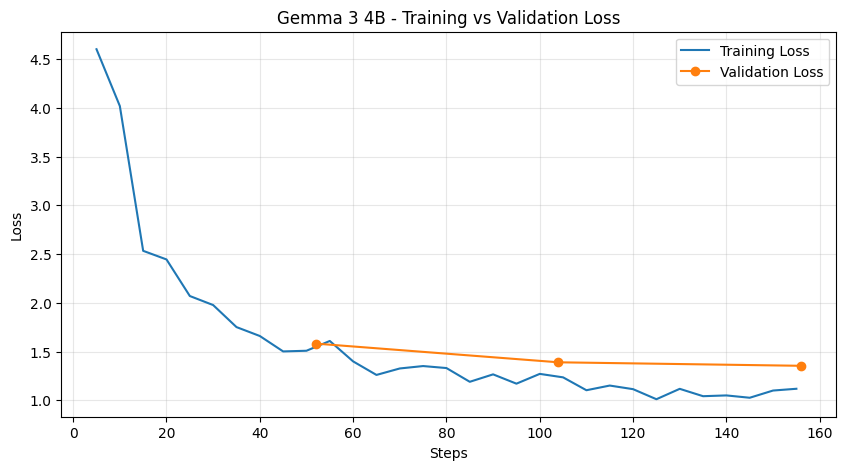

In [33]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(trainer.state.log_history)

train = history_df.dropna(subset=["loss"])
valid = history_df.dropna(subset=["eval_loss"])

plt.figure(figsize=(10, 5))

plt.plot(train["step"], train["loss"], label="Training Loss")
plt.plot(valid["step"], valid["eval_loss"],
         marker="o", label="Validation Loss")

plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("Gemma 3 4B - Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [34]:
model.save_pretrained("gemma3-khmer-lora")
tokenizer.save_pretrained("gemma3-khmer-lora")

print("LoRA adapter saved!")

Unsloth: Restored added_tokens_decoder metadata in gemma3-khmer-lora/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma3-khmer-lora.


LoRA adapter saved!


In [35]:
from unsloth import FastModel

FastModel.for_inference(model)

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Gemma3ForConditionalGeneration(
      (model): Gemma3Model(
        (vision_tower): SiglipVisionModel(
          (embeddings): SiglipVisionEmbeddings(
            (patch_embedding): Conv2d(3, 1152, kernel_size=(14, 14), stride=(14, 14), padding=valid)
            (position_embedding): Embedding(4096, 1152)
          )
          (encoder): SiglipEncoder(
            (layers): ModuleList(
              (0-26): 27 x SiglipEncoderLayer(
                (layer_norm1): LayerNorm((1152,), eps=1e-06, elementwise_affine=True)
                (self_attn): SiglipAttention(
                  (k_proj): Linear4bit(in_features=1152, out_features=1152, bias=True)
                  (v_proj): Linear4bit(in_features=1152, out_features=1152, bias=True)
                  (q_proj): Linear4bit(in_features=1152, out_features=1152, bias=True)
                  (out_proj): Linear4bit(in_features=1152, out_features=1152, bias=True)
                )
 

In [36]:

import torch

def ask_gemma(question, max_new_tokens=256):

    messages = [
        {
            "role": "user",
            "content": question
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            input_ids=inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        outputs[0][inputs.shape[-1]:],
        skip_special_tokens=True
    )

    return answer.strip()


In [37]:
questions = [
    "តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី?",
    "តើអតិថិជនត្រូវមានអាយុប៉ុន្មានដើម្បីស្នើសុំឥណទាន?",
    "តើធនាគារ អេស៊ីលីដា ផ្តល់សេវាកម្មអ្វីខ្លះ?"
]

for i, question in enumerate(questions, 1):

    print("=" * 70)
    print(f"QUESTION {i}:")
    print(question)

    print("\nMODEL ANSWER:")
    print(ask_gemma(question))
    print()

QUESTION 1:
តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី?

MODEL ANSWER:
ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណអេឡិចត្រូនិក ដែលផ្តល់ជូនអតិថិជន ដើម្បីប្រើប្រាស់ក្នុងការទូទាត់ទំនិញ និងសេវាកម្ម តាមរយៈម៉ាស៊ីនឆូតកាត ឬម៉ាស៊ីនឆូតអេស៊ីលីដា របស់ធនាគារ អេស៊ីលីដា ភីអិលស៊ី តាមរយៈប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា។

QUESTION 2:
តើអតិថិជនត្រូវមានអាយុប៉ុន្មានដើម្បីស្នើសុំឥណទាន?

MODEL ANSWER:
អតិថិជនត្រូវមានអាយុយ៉ាងតិច ១៨ ឆ្នាំ ទៅ ១១០ឆ្នាំ ដើម្បីស្នើសុំឥណទាន។

QUESTION 3:
តើធនាគារ អេស៊ីលីដា ផ្តល់សេវាកម្មអ្វីខ្លះ?

MODEL ANSWER:
ធនាគារ អេស៊ីលីដា ផ្តល់សេវាកម្មដូចខាងក្រោម៖ \n - ផ្តល់សេវាបើកគណនី និងគ្រប់គ្រងគណនីសម្រាប់អតិថិជនគ្រប់ប្រភេទ។ \n - ផ្តល់សេវាផ្ទេរប្រាក់រវាងគណនីក្នុង និងក្រៅធនាគារ។ \n - ផ្តល់សេវាដកប្រាក់រវាងគណនីក្នុង និងក្រៅធនាគារ។ \n - ផ្តល់សេវាដកប្រាក់តាមរយៈម៉ាស៊ីនអេស៊ីលីដា។ \n - ផ្តល់សេវាដកប្រាក់តាមរយៈអ៉ីអនឡាញ។ \n - ផ្តល់សេវាដកប្រាក់តាមរយៈធនាគារឯកទេសផ្សេងៗ។ \n - ផ្តល់សេវាដកប្រាក់តាមរយៈធនាគារជាតិផ្សេងៗ។ \n - ផ្តល់សេវាដកប្រាក់តាមរយៈធនាគារអន្តរជាតិផ្សេងៗ។ \n - ផ្តល់សេវាដកប្រាក់តាមរយៈធ

In [38]:
questions = [
    "តើ​ប័ណ្ណឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា ធម្មតា មាន​សុពលភាព​ប្រើប្រាស់​បាន​រហូតដល់​រយៈពេល​ប៉ុន្មាន​ឆ្នាំ",
    "តើ​ត្រូវ​ធ្វើ​ដូចម្តេច ប្រសិន​បើ​ខ្ញុំ​បាត់ ប័ណ្ណឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា ធម្មតា?",
    "តើ​ប័ណ្ណឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា មាស ជាអ្វី?"
]

for i, question in enumerate(questions, 1):

    print("=" * 70)
    print(f"QUESTION {i}:")
    print(question)

    print("\nMODEL ANSWER:")
    print(ask_gemma(question))
    print()

QUESTION 1:
តើ​ប័ណ្ណឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា ធម្មតា មាន​សុពលភាព​ប្រើប្រាស់​បាន​រហូតដល់​រយៈពេល​ប៉ុន្មាន​ឆ្នាំ

MODEL ANSWER:
ប័ណ្ណឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា ធម្មតា មាន​សុពលភាព​ប្រើប្រាស់​បាន​រហូត​ដល់​រយៈពេល​ ១០ឆ្នាំ ។

QUESTION 2:
តើ​ត្រូវ​ធ្វើ​ដូចម្តេច ប្រសិន​បើ​ខ្ញុំ​បាត់ ប័ណ្ណឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា ធម្មតា?

MODEL ANSWER:
លោក-លោកស្រី ត្រូវ​ធ្វើ​ការ​ស្នើសុំ​ប័ណ្ណ​ប្តូរ​ប័ណ្ណឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា ធម្មតា ឡើងវិញ នៅ​ការិយាល័យ​ធនាគារ​ឯកទេស អេស៊ីលីដា ដែល​នៅ​ជិត​លោក-លោកស្រី​បំផុត ហើយ​ត្រូវ​បំពេញ​ពាក្យ​ស្នើសុំ​ប័ណ្ណ​ប្តូរ​ប័ណ្ណ​ឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា ធម្មតា ឡើងវិញ ជាមួយ​នឹង​ឯកសារ​សម្គាល់​អត្តសញ្ញាណ​របស់​លោក-លោកស្រី ដែល​មាន​សុពលភាព​ប្រើប្រាស់​បាន​រហូត​ដល់​ថ្ងៃ​ផុត​កំណត់​របស់​ប័ណ្ណ​ឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា ធម្មតា ដែល​បាន​បោះផ្សាយ​ឡើង​វិញ។

QUESTION 3:
តើ​ប័ណ្ណឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា មាស ជាអ្វី?

MODEL ANSWER:
ប័ណ្ណឥណពន្ធ​យូភីអាយ​អេស៊ីលីដា មាស គឺជា ប័ណ្ណអេឡិចត្រូនិក ដែល​ផ្តល់​ជូន​អតិថិជន​របស់​ធនាគារ​ឯកទេស អេស៊ីលីដា ភីអិលស៊ី ដើម្បី​ប្រើប្រាស់​ជាមួយ​ម៉ាស៊ីន អេស៊ីលីដា ម៉ាស៊ីន អេស៊ីលីដា អេធីអឹម